# 03 · Optimizers

Plain gradient descent ($\theta \leftarrow \theta - \eta\,g$) uses one global step size and forgets history. Three classic fixes, each built here from scratch on the same network and the same starting weights:

**SGD + Momentum** — keep a running velocity, so consistent directions accelerate and zig-zags cancel:
$$v \leftarrow \mu v - \eta g,\qquad \theta \leftarrow \theta + v$$

**RMSprop** — divide each step by a running RMS of that parameter's gradients, so steep directions are damped and flat ones are boosted:
$$c \leftarrow \rho c + (1-\rho)g^2,\qquad \theta \leftarrow \theta - \eta\,\frac{g}{\sqrt{c}+\epsilon}$$

**Adam** — momentum *and* RMS scaling, with bias correction because $m,v$ start at zero:
$$m \leftarrow \beta_1 m + (1-\beta_1)g,\quad v \leftarrow \beta_2 v + (1-\beta_2)g^2,\quad \hat m=\frac{m}{1-\beta_1^t},\ \hat v=\frac{v}{1-\beta_2^t},\quad \theta \leftarrow \theta - \eta\,\frac{\hat m}{\sqrt{\hat v}+\epsilon}$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## Activations and loss
Stateless pieces reused as-is (`ReLU`, `Sigmoid`, `MSELoss`). They only compute forward values and gradients — no update rule baked in.

In [2]:
class Sigmoid:
    def __init__(self):
        self.output = None
    
    def forward(self, z):
        self.output = 1 / (1 + np.exp(-z))
        return self.output
    
    def backward(self, grad_output):
        # Gradient: sigmoid'(z) = sigmoid(z) * (1 - sigmoid(z))
        return grad_output * self.output * (1 - self.output)


class ReLU:
    def __init__(self):
        self.input = None
    
    def forward(self, z):
        self.input = z
        return np.maximum(0, z)
    
    def backward(self, grad_output):
        # Gradient: relu'(z) = 1 if z > 0 else 0
        return grad_output * (self.input > 0).astype(float)


class MSELoss:
    def forward(self, y_pred, y_true):
        return np.mean((y_pred - y_true) ** 2)
    
    def backward(self, y_pred, y_true):
        return 2 * (y_pred - y_true) / y_true.shape[0]

## A Dense layer that *returns* gradients
The earlier `Dense` updated its own weights inside `backward`. To plug in different optimizers it must hand the raw gradients back instead, so the update rule lives in one place — the optimizer.

In [3]:
class Dense:
    def __init__(self, input_dim, output_dim, weights=None, bias=None):
        self.weights = weights.copy() if weights is not None else np.random.randn(input_dim, output_dim) * 0.5
        self.bias = bias.copy() if bias is not None else np.zeros((1, output_dim))
        self.input = None

    def forward(self, x):
        self.input = x
        return np.dot(x, self.weights) + self.bias

    def backward(self, grad_output):
        grad_weights = np.dot(self.input.T, grad_output)
        grad_bias = np.sum(grad_output, axis=0, keepdims=True)
        grad_input = np.dot(grad_output, self.weights.T)
        return grad_input, grad_weights, grad_bias

## A fixed network, so every optimizer trains the same thing
`2 → 8 (ReLU) → 1 (Sigmoid)`. `backward` returns `(params, grads)` as parallel lists.

In [4]:
class MLP:
    """Fixed architecture: 2 -> 8 (ReLU) -> 1 (Sigmoid), so every optimizer trains the same net."""

    def __init__(self, w1, b1, w2, b2):
        self.d1 = Dense(2, 8, w1, b1)
        self.a1 = ReLU()
        self.d2 = Dense(8, 1, w2, b2)
        self.a2 = Sigmoid()

    def forward(self, x):
        return self.a2.forward(self.d2.forward(self.a1.forward(self.d1.forward(x))))

    def backward(self, grad):
        grad = self.a2.backward(grad)
        grad, gw2, gb2 = self.d2.backward(grad)
        grad = self.a1.backward(grad)
        _, gw1, gb1 = self.d1.backward(grad)
        params = [self.d1.weights, self.d1.bias, self.d2.weights, self.d2.bias]
        grads = [gw1, gb1, gw2, gb2]
        return params, grads

## The optimizers
Each keeps its own per-parameter state (velocity, squared-gradient cache, moments) and updates parameters **in place**.

In [5]:
class SGDMomentum:
    def __init__(self, lr=0.1, momentum=0.9):
        self.lr = lr
        self.momentum = momentum
        self.velocities = None

    def step(self, params, grads):
        if self.velocities is None:
            self.velocities = [np.zeros_like(p) for p in params]
        for p, g, v in zip(params, grads, self.velocities):
            v *= self.momentum
            v -= self.lr * g
            p += v

In [6]:
class RMSprop:
    def __init__(self, lr=0.01, decay=0.9, eps=1e-8):
        self.lr = lr
        self.decay = decay
        self.eps = eps
        self.cache = None

    def step(self, params, grads):
        if self.cache is None:
            self.cache = [np.zeros_like(p) for p in params]
        for p, g, c in zip(params, grads, self.cache):
            c *= self.decay
            c += (1 - self.decay) * g ** 2
            p -= self.lr * g / (np.sqrt(c) + self.eps)

In [7]:
class Adam:
    def __init__(self, lr=0.01, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.m = None
        self.v = None
        self.t = 0

    def step(self, params, grads):
        if self.m is None:
            self.m = [np.zeros_like(p) for p in params]
            self.v = [np.zeros_like(p) for p in params]
        self.t += 1
        for i, (p, g) in enumerate(zip(params, grads)):
            self.m[i] = self.beta1 * self.m[i] + (1 - self.beta1) * g
            self.v[i] = self.beta2 * self.v[i] + (1 - self.beta2) * g ** 2
            m_hat = self.m[i] / (1 - self.beta1 ** self.t)
            v_hat = self.v[i] / (1 - self.beta2 ** self.t)
            p -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

## Training loop
Optimizer-agnostic: any object with `.step(params, grads)` works.

In [8]:
def train(model, optimizer, X, y, loss_fn, epochs):
    history = []
    for _ in range(epochs):
        y_pred = model.forward(X)
        history.append(loss_fn.forward(y_pred, y))
        params, grads = model.backward(loss_fn.backward(y_pred, y))
        optimizer.step(params, grads)
    return history

## Experiment: XOR, identical starting weights

XOR needs the hidden layer, so the optimizer genuinely has to navigate a non-trivial landscape. Fresh `MLP` per optimizer, but copied from the same initial arrays — differences in the curves come only from the update rule. Try changing `lr` / `momentum` / `EPOCHS`.

In [9]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

w1 = np.random.randn(2, 8) * 0.5
b1 = np.zeros((1, 8))
w2 = np.random.randn(8, 1) * 0.5
b2 = np.zeros((1, 1))

EPOCHS = 2000
loss_fn = MSELoss()
optimizers = {
    "SGD+Momentum": SGDMomentum(lr=0.1, momentum=0.9),
    "RMSprop": RMSprop(lr=0.05),
    "Adam": Adam(lr=0.05),
}

histories, models = {}, {}
for name, opt in optimizers.items():
    models[name] = MLP(w1, b1, w2, b2)   # fresh model, identical starting weights
    histories[name] = train(models[name], opt, X, y, loss_fn, EPOCHS)
    preds = (models[name].forward(X) >= 0.5).astype(int).ravel().tolist()
    print(f"{name:<14} final_loss={histories[name][-1]:.6f}  preds={preds}  target={y.astype(int).ravel().tolist()}")
    assert histories[name][-1] < 0.05, f"{name} failed to converge on XOR"

SGD+Momentum   final_loss=0.000246  preds=[0, 1, 1, 0]  target=[0, 1, 1, 0]


RMSprop        final_loss=0.000000  preds=[0, 1, 1, 0]  target=[0, 1, 1, 0]


Adam           final_loss=0.000013  preds=[0, 1, 1, 0]  target=[0, 1, 1, 0]


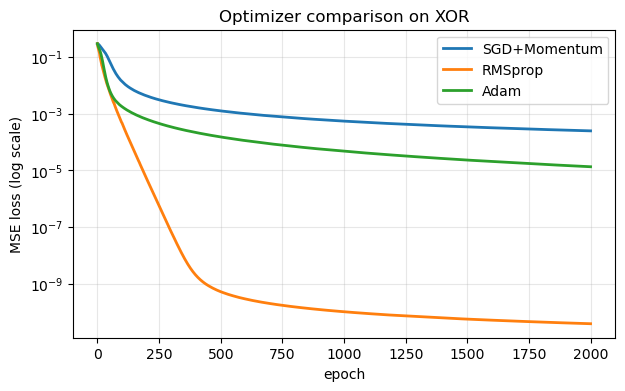

In [10]:
plt.figure(figsize=(7, 4))
for name, hist in histories.items():
    plt.plot(hist, label=name, linewidth=2)
plt.yscale("log")
plt.xlabel("epoch"); plt.ylabel("MSE loss (log scale)")
plt.title("Optimizer comparison on XOR")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

RMSprop and Adam adapt step size per parameter and typically drop the loss fastest here; momentum is competitive but more sensitive to `lr`/`momentum`.

**Next: `04_regularization`** — a network that fits the training set isn't necessarily a good one. L2, dropout and batch norm fight overfitting.